> **Legacy research report.** The maintained entry point is `python scripts/percolation.py`. This notebook reads the same results from `data/percolation/`; it does not define a separate experiment or output directory. See `docs/percolation.md` for the current interface.


# Percolation Research

This notebook completes the audit, theoretical review, and random edge-failure study on our frozen ConceptNet graph.

The notebook contains exposition and calls for displaying completed results.

Algorithm implementations, graph processing, simulations, statistics, and plotting live in `src/percolation/`. Shared project inputs are read only. Everything generated by this section stays inside the repository.

The completed study uses 150 fixed queries, 30 independent repetitions, 11 failure probabilities, with independent edge failures. A separate 51-point component-size sweep examines fragmentation without changing the query workload. All reported results are calculated from the saved run files.

NOTE: Use the authors’ `PC5253-KG` environment with Python **3.11.16**. From the project root, install `python -m pip install -r requirements.txt`. This shared file retains the original project pins and includes the percolation and notebook dependencies. Run `python -m src.environment` before reproducing the study. Select the `PC5253-KG` notebook kernel.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/percolation").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks/legacy"))
from src.environment import check_environment
check_environment()
from _support.report import StudyReport
report = StudyReport()
report.overview()

## Section A: Audit and Interpretation

### 1. Standardisation: what exactly are we deleting?

ConceptNet assertions describe relations between concepts.

Several assertions may connect the same pair, with different categories or directions. The following is a concise official API interpretation. [ConceptNet API documentation](https://github.com/commonsense/conceptnet5/wiki/API)

| Item | ConceptNet assertions | Our frozen projection |
| --- | --- | --- |
| Endpoints | Start and end concept identifiers | **unordered** |
| Relation | A typed relation, such as `IsA` | **Union** of retained categories |
| Direction | Depends on the relation | **Ignored** |
| Multiple assertions | Distinct assertions can connect the same pair | **One simple edge** |
| Weight | Evidence / believability score | **unused** |
| Provenance | Dataset, sources, license | **unused** |

### 2. Reminder: sampled graph and largest component

For acquisition and construction details of the authoritative experimental graph, refer to the README.

The earlier 1,325-edge graph belongs to the Lexicographic baseline. Its leaf ratio, bridge ratio, and hub-removal results should **not** be used to describe the current graph.

Use this same frozen graph for query selection and percolation. The larger source is relevant to provenance and sampling analysis.

### 3. Concerns inherited from graph construction

These concerns mainly belong to the preceding data-construction work, but they still affect how we interpret percolation.

- **Sampling preference.** Greedy sampling favours internal connectivity. Its stronger connectivity is partly a consequence of that selection criterion. The comparison with the historical sample below is structural context, not a controlled estimate of a general sampling effect.

- **Node identity and filtering.** Retain the documented rules for English base concepts, relation filtering, self-loop removal, and merging repeated or reversed edges. Do not silently change these during percolation. Term and sense merging can change shortcuts and degrees.

- **Weights.** Keep the main analysis unweighted. ConceptNet evidence weights and NetworkX path distances have different meanings. Passing evidence weights directly as distances would make strongly supported edges longer to traverse. [NetworkX shortest-path documentation](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.shortest_paths.generic.shortest_path_length.html)

- **Selection after preliminary experiments.** According to the README, the Greedy graph was chosen after structural comparisons and a robustness pre-check. The historical pre-check used graph-specific query sets; it does not isolate sampling effects on identical queries.


NOTE: Deleting an edge removes the entire projected connection, including its bundled relation categories. Paths describe structural association, rather than verified semantic reasoning.


## Section B: Retrospective on Theoretical Percolation

### 1. Brief walkthrough of bond percolation

We consider deleting links, rather than nodes. Each edge independently survives with probability $p=1-q$. All nodes remain in place.

The number of deleted edges is $M_{\rm deleted}\sim\mathrm{Binomial}(m,q)$. Its expectation is $mq$ and its variance is $mq(1-q)$.

Removing a fixed number of randomly selected edges is another possible experiment. It is not exactly the independent-failure model used here.

Let $n_k$ be the number of nodes of degree $k$. Then:

$$P(k)=n_k/N,\qquad \langle k\rangle=\sum_k kP(k)=2m/N,$$
$$\langle k^2\rangle=\sum_k k^2P(k).$$

The second moment captures degree heterogeneity. Following a randomly chosen edge is more likely to reach a high-degree node: the reached degree has probability $kP(k)/\langle k\rangle$.

### 2. Theoretical threshold: derive it, then state its assumptions

After arriving along one edge, a degree-$k$ node has $k-1$ further edges. The expected number of surviving onward edges is (the expectation of excess degree times p):

$$B(p)=p\sum_k(k-1)\frac{kP(k)}{\langle k\rangle}
=p\frac{\langle k^2\rangle-\langle k\rangle}{\langle k\rangle}.$$

In a large, locally tree-like, uncorrelated configuration-model network, the branching condition is $B(p)>1$. Setting it to one gives:

$$p_c=\frac{\langle k\rangle}{\langle k^2\rangle-\langle k\rangle},\qquad q_c=1-p_c.$$

An admissible threshold requires the denominator to be positive and $p_c\leq1$. If the excess-degree mean is below one, this reference ensemble has no supercritical regime for admissible survival probabilities; equality is the boundary case.

**This degree-based threshold is a reference for a large, locally tree-like, uncorrelated network.** Our graph is finite, clustered, and deliberately sampled; the formula is not its exact fragmentation threshold. Here q means failure probability.

For the reference curve in Section C, define $G_0(x)=\sum_k P(k)x^k$ and $G_1(x)=\sum_k kP(k)x^{k-1}/\langle k\rangle$. The smallest solution of $u=1-p+pG_1(u)$ gives $S_{\rm ref}=1-G_0(u)$.

### 3. Why use a configuration-model reference?

The configuration model fixes each node's degree, gives it that many half-edges (stubs), and randomly pairs the stubs to form edges. For example, degrees 3, 2, 2, and 1 give eight stubs and four edges. Degrees are retained, but the identities of neighbours are random. The standard model can contain self-loops and parallel edges. [Configuration-model definition](https://networkx.org/documentation/stable/reference/generated/networkx.generators.degree_seq.configuration_model.html)

Its purpose here is to ask what connectivity would be expected from degree information alone, without deliberately preserving the graph's communities, triangles, or relation meanings. Under the large, locally tree-like, uncorrelated approximation, following an edge reaches degree k with probability $kP(k)/\langle k\rangle$. Excluding the arrival edge leaves k−1 onward edges, of which a fraction p survive on average. Thus B(p) is an expected onward branch count, not a probability; it can exceed one. [Percolation reference](https://arxiv.org/html/cond-mat/0007300v2)

NOTE: We do not rewire the experimental graph or simulate a new configuration-model graph. We insert its empirical degree distribution into the generating-function equations above. All failure experiments still use the frozen ConceptNet graph. The resulting curve and threshold are assumption-dependent references.


**Implementation:** `src/percolation/theory.py::degree_table()` counts nodes of each degree to obtain P(k) and the cumulative tail P(K≥k); `export_degrees()` applies it to the frozen and historical samples. The figure uses positive degrees/probabilities on log–log axes. A broad tail alone does not establish a scale-free model.

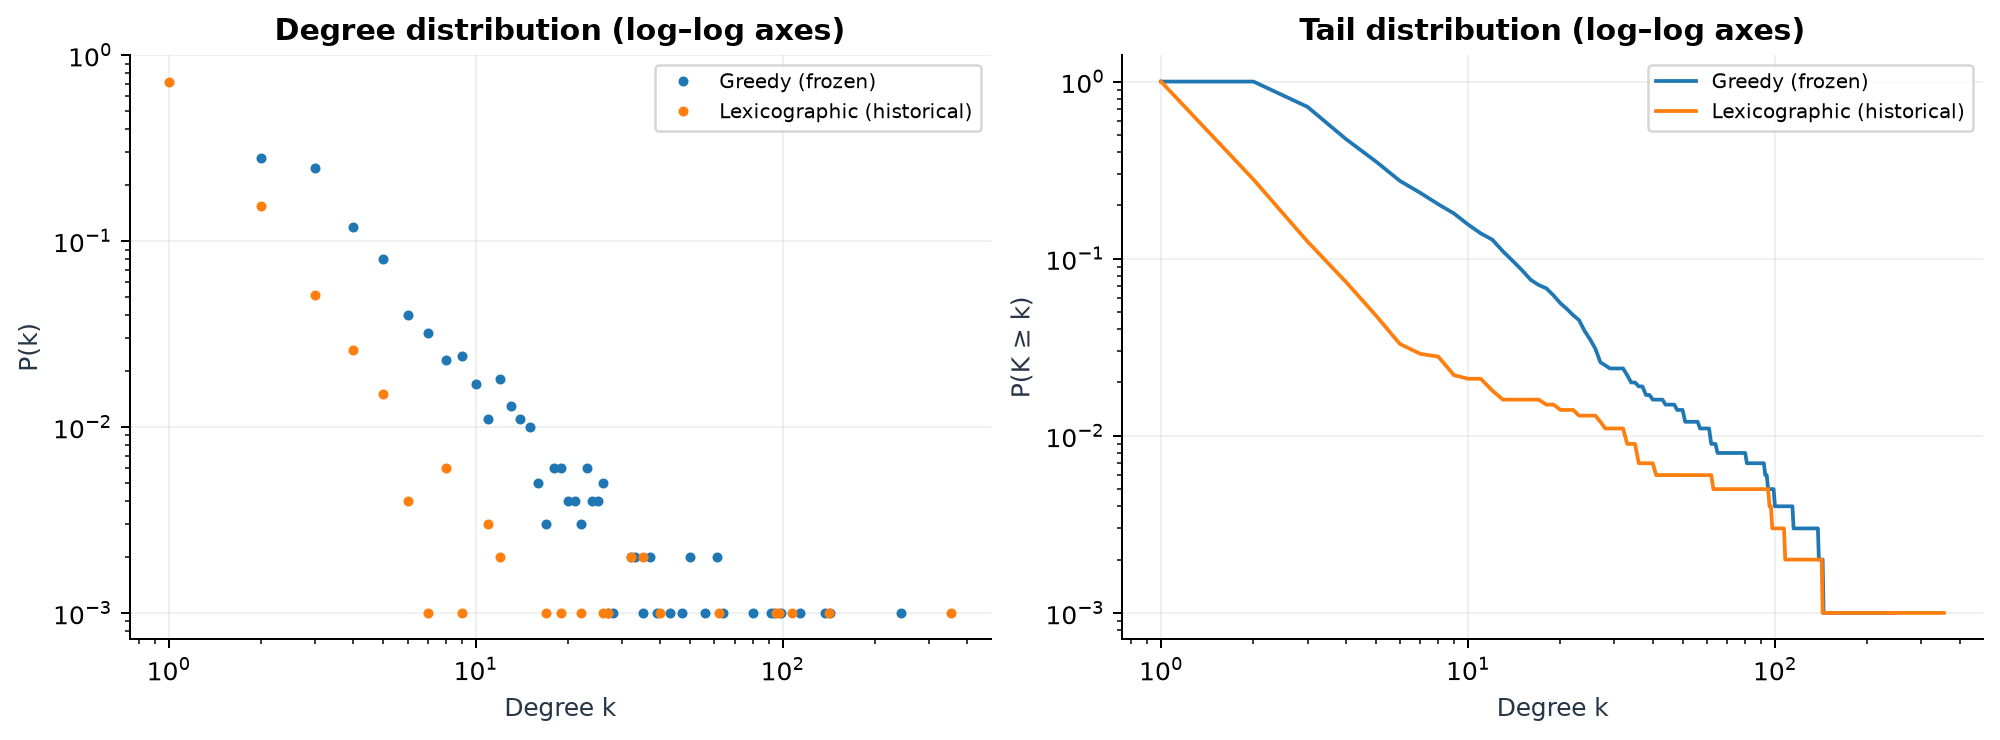

In [2]:
report.figure("degree_structure")

## Section C: Percolation on the Frozen Graph

### 1. Freeze the queries

Select 75 unordered pairs with original shortest-path distance exactly two, and 75 at distance exactly three. Each group is sampled uniformly without replacement from all eligible pairs. The resulting 150-query workload is saved before formal failures (percolation), with its original distances and a recorded hash.

NOTE: Concept endpoints can repeat across different queries. The same unordered pair cannot repeat. `(A, B)` and `(A, C)` are allowed, but `(B, A)` duplicates `(A, B)`.

- Sample pairs rather than paths, avoiding extra selection opportunities for pairs with many routes. Selecting a source first and then one of its targets would generally produce another pair distribution.

The same queries are used for every repetition and failure probability. Endpoint reuse is reported below.

In [3]:
report.query_audit()

item,value
Eligible distance-2 pairs,92941
Eligible distance-3 pairs,300923
Selected unique pairs,150
Distinct endpoint concepts,255
Maximum endpoint reuse,4
Queries with person as an endpoint,0


**Implementation:** `src/percolation/core.py::candidate_pairs()` uses shortest-path searches with cutoff three and keeps each unordered pair once. `sample_queries()` samples 75 pairs per distance without replacement, then counts both endpoints across queries. The figure shows the 12 most reused concepts; the counts are endpoint appearances, not path participation.

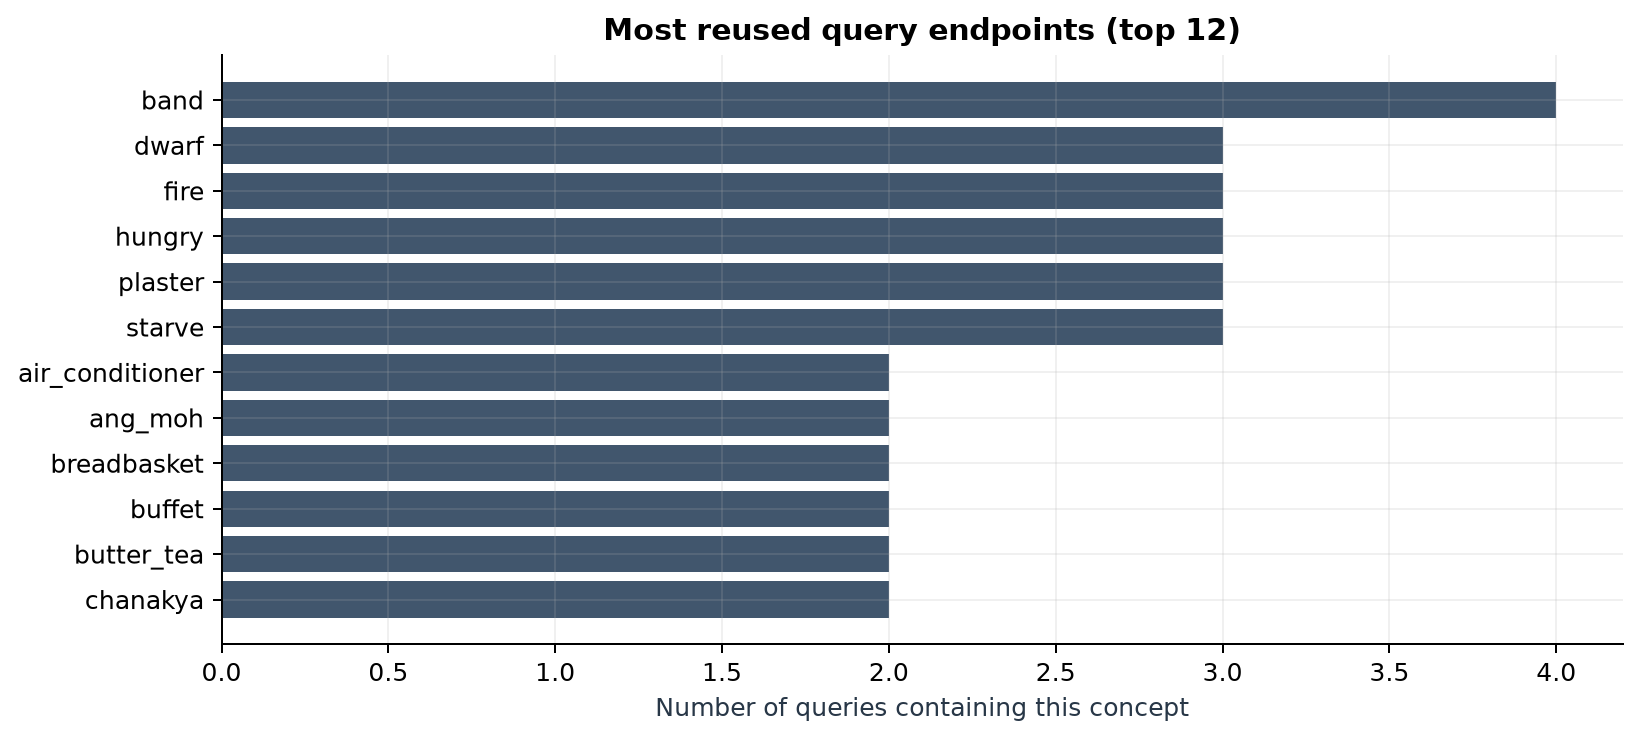

In [4]:
report.figure("endpoint_reuse")

### 2. Define shared failure scenarios

For each repetition, one independent uniform value in $[0,1)$ is assigned to every original edge in a stable canonical ordering. An edge fails when its value is below $q$.

All q values within a repetition use the same edge-specific values. Fresh random values are assigned in each repetition. The edge order and draw matrix are saved for reproducing.

**Why keep a fixed edge-to-draw mapping**:

A shared seed alone is insufficient if random numbers are assigned to different edges. What matters is a fixed edge-to-draw mapping. Increasing q therefore gives nested damage. Query selection and failure generation use separate randomisation streams.

### 3. Failure range and repetitions

The main study uses $q\in\{0,0.1,\ldots,1.0\}$ and 30 independent repetitions, giving 330 evaluated scenarios. A separate sweep at spacing 0.02 examines component sizes using the same 30 damage scenarios.

An independent single-scenario pilot checked practicality. The final count remained fixed at 30; the final count was fixed before the formal simulations.

- The 0.02 fragmentation sweep is a diagnostic, not a second query-selection exercise.


### 4. Report query availability and structural connectivity

For repetition $r$:

$$Q_r(q)=\frac1{150}\sum_{i=1}^{150}\mathbf{1}\{d_{G_{r,q}}(u_i,v_i)\leq3\},$$
$$S_r(q)=\frac{|\mathrm{LCC}(G_{r,q})|}{1,000}.$$

Disconnected pairs have infinite distance. Separate $Q_2$ and $Q_3$ use their respective 75-query denominators; since the groups are equally sized, $Q=(Q_2+Q_3)/2$.

A query succeeds if **any** surviving route has at most three edges. Checking only one saved original path would be incorrect.

For this experiment, $Q(0)=S(0)=1$; at $q=1$, $Q=0$ and $S=1/1,000$. A single isolated node is still a component.

All confidence bands below are pointwise 95% Student-t intervals for the repetition mean: $\bar x\pm t_{0.975,29}s/\sqrt{30}$. Sample standard deviations are also saved. Numerical limits are not clipped in the exported tables; plotted axes show the meaningful fraction range. These are not simultaneous confidence bands.

In [5]:
report.table("summary")

q,Q_mean,Q2_mean,Q3_mean,S_mean,longer_route_mean,disconnected_mean
0.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
0.2000,0.8096,0.8964,0.7227,0.9865,0.1684,0.0220
0.3000,0.6740,0.7893,0.5587,0.9664,0.2644,0.0616
0.4000,0.5247,0.6560,0.3933,0.9325,0.3536,0.1218
0.5000,0.3824,0.5018,0.2631,0.8798,0.4038,0.2138
0.7000,0.1360,0.2040,0.0680,0.6939,0.3733,0.4907
0.9000,0.0124,0.0231,0.0018,0.2269,0.0569,0.9307
1.0000,0.0000,0.0000,0.0000,0.0010,0.0000,1.0000


**Implementation:** `src/percolation/core.py::damage_graph()` applies each original-edge draw to the selected q while retaining every node. `evaluate()` searches up to three hops for query success and computes connected components for S. `src/percolation/statistics.py::summarize()` groups the 30 repetitions at each q; `mean_interval()` calculates the mean, sample SD, and pointwise t interval. The same failure draws are reused across q.

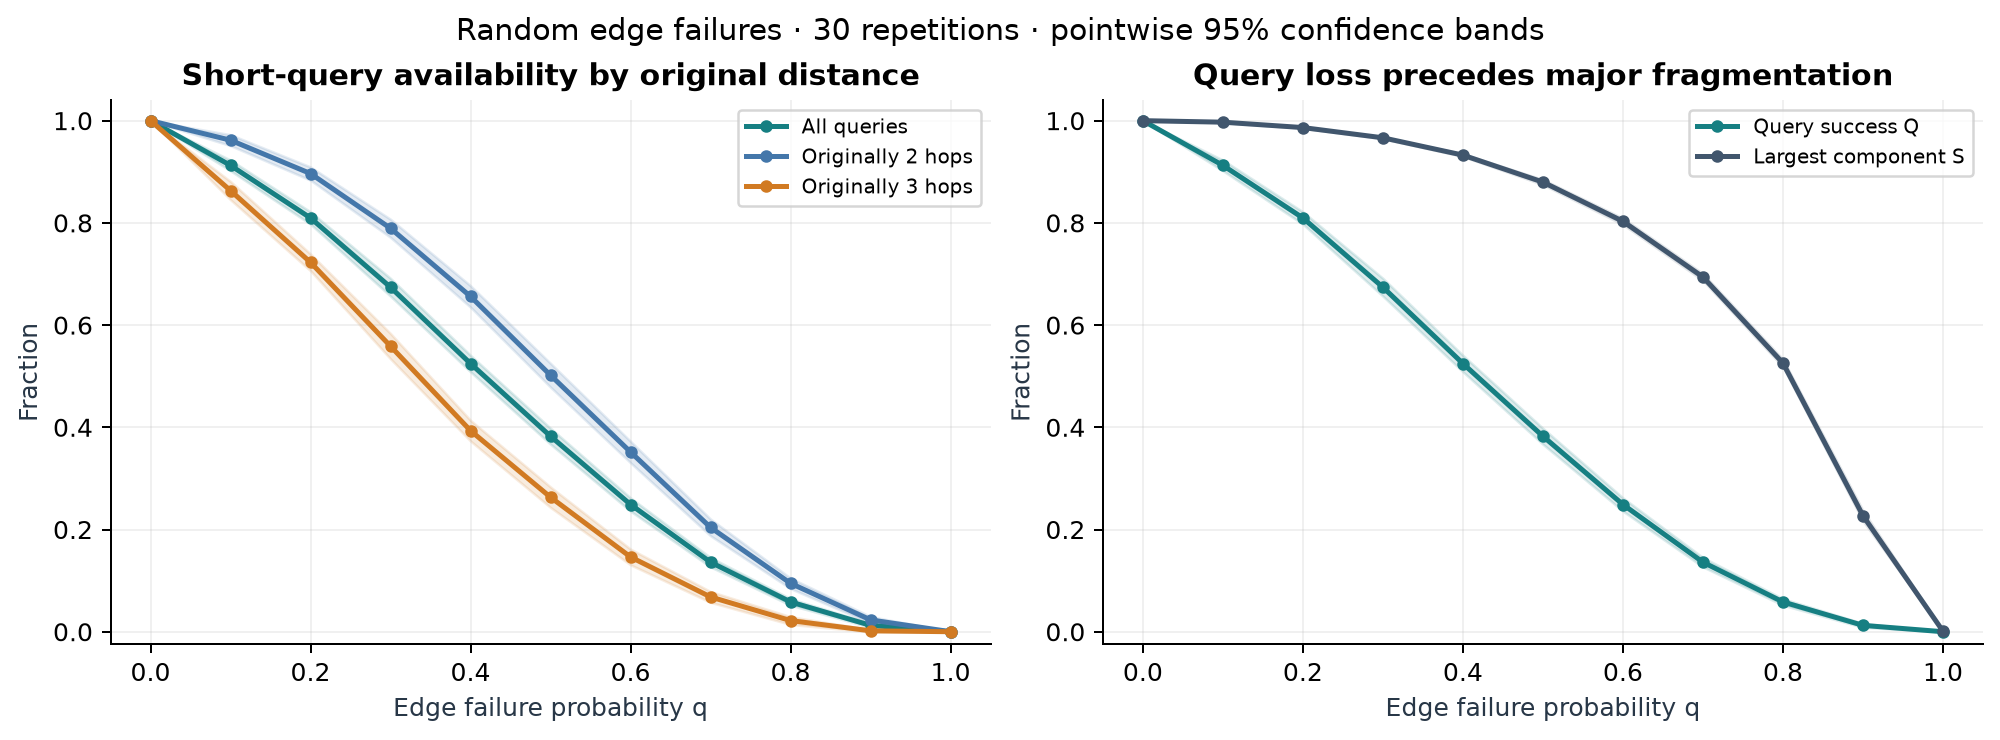

In [6]:
report.figure("baseline_percolation")

### 5. Does $S$ explain $Q$?

Every fixed query belongs to exactly one case after failure:

- Survive: Reachable within three hops.
- Connected: but requiring more than three hops.
- Disconnected.

These fractions sum to one. Component membership distinguishes the last two outcomes, while a depth-three search establishes success. Endpoints need not be in the largest component to succeed.

**Implementation:** `src/percolation/core.py::evaluate()` labels a query successful when a depth-three search reaches its target. Otherwise, component membership separates a longer connected route from disconnection. `src/percolation/experiment.py::run()` saves these fractions and each repetition's S and Q. The left panel shows mean outcome fractions; the right overlays the 30 (S,Q) observations at each of q=0.3, 0.5, and 0.7 in different colours. The combined scatter is descriptive; correlations in the table are still computed separately within each q.

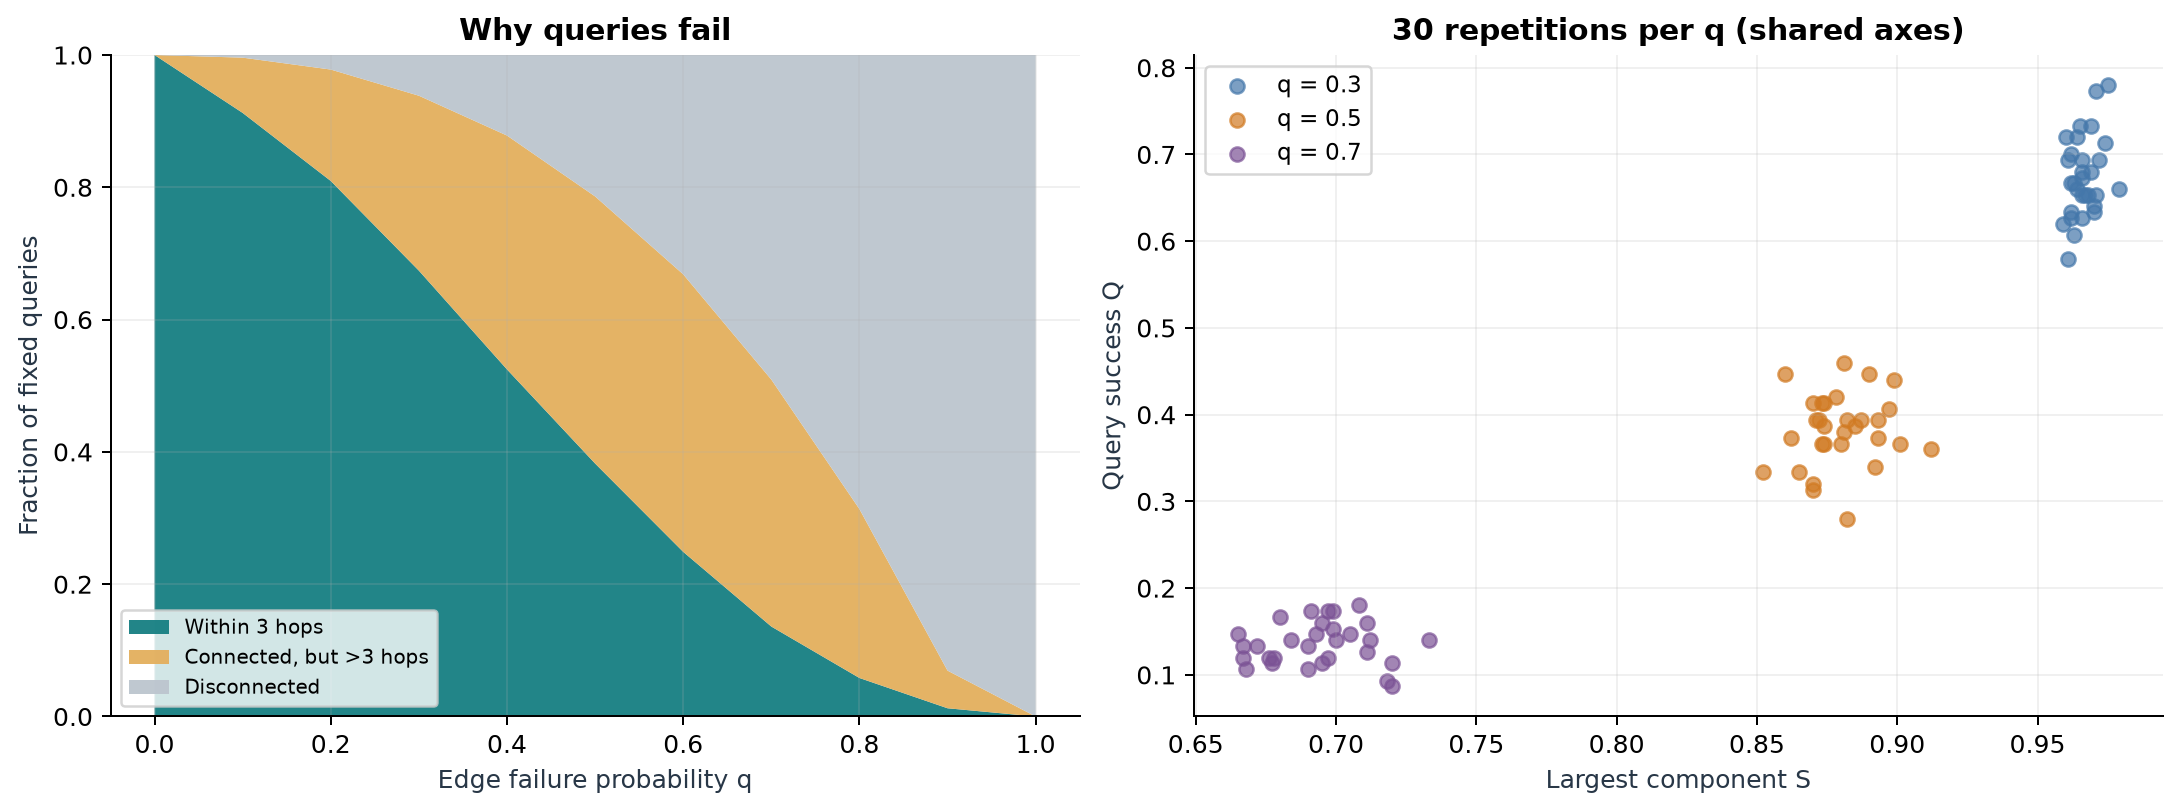

In [7]:
report.figure("query_failure_analysis")

In [8]:
report.table("within_q_correlations")

q,pearson_r_within_q,repetitions
0.2000,-0.03006639160527641,30
0.3000,0.3496130440363574,30
0.4000,0.010005830575523612,30
0.5000,0.13101662405823242,30
0.7000,0.012322123550322741,30


**Result:**
A pooled correlation across all $q$ values could largely reflect their shared response to increasing damage. The table instead gives descriptive correlations among repetitions at fixed $q$.

The outcome breakdown supplies a more direct interpretation: short-query availability can disappear through route lengthening, even when much of the graph remains in one component. It concludes that component size alone does not describe the three-hop criterion.

### 6. Largest component and all remaining components

The left panel compares measured S with the configuration-model reference from Section B. The right panel shows the fraction of original nodes belonging to **all components other than one largest component**, including isolated nodes:

$$S_{\rm small}(q)=\frac{\sum_{C\ne C_{\max}}|C|}{N}=1-S(q).$$

NOTE: “Small components” is a label for everything outside the largest component; it does not impose a size cutoff. The ratio counts nodes, not the number of components. It is exactly the complement of S, so it offers a clearer presentation rather than independent evidence about fragmentation. It cannot distinguish one sizeable second component from many isolated nodes with the same total size. At q=1 it equals 999/1,000. No empirical critical threshold is inferred from this curve.


**Implementation:** `src/percolation/experiment.py::run()` applies the saved draws on the 0.02 q-grid, computes component sizes, and records S and 1−S for each repetition. `summarize()` aggregates the 30 repetitions. `src/percolation/theory.py::configuration_curve()` iterates u=1−p+pG₁(u), starting at zero, until the change is below 10⁻¹², then calculates 1−G₀(u). The reference uses the original empirical degrees and does not generate replacement edges.

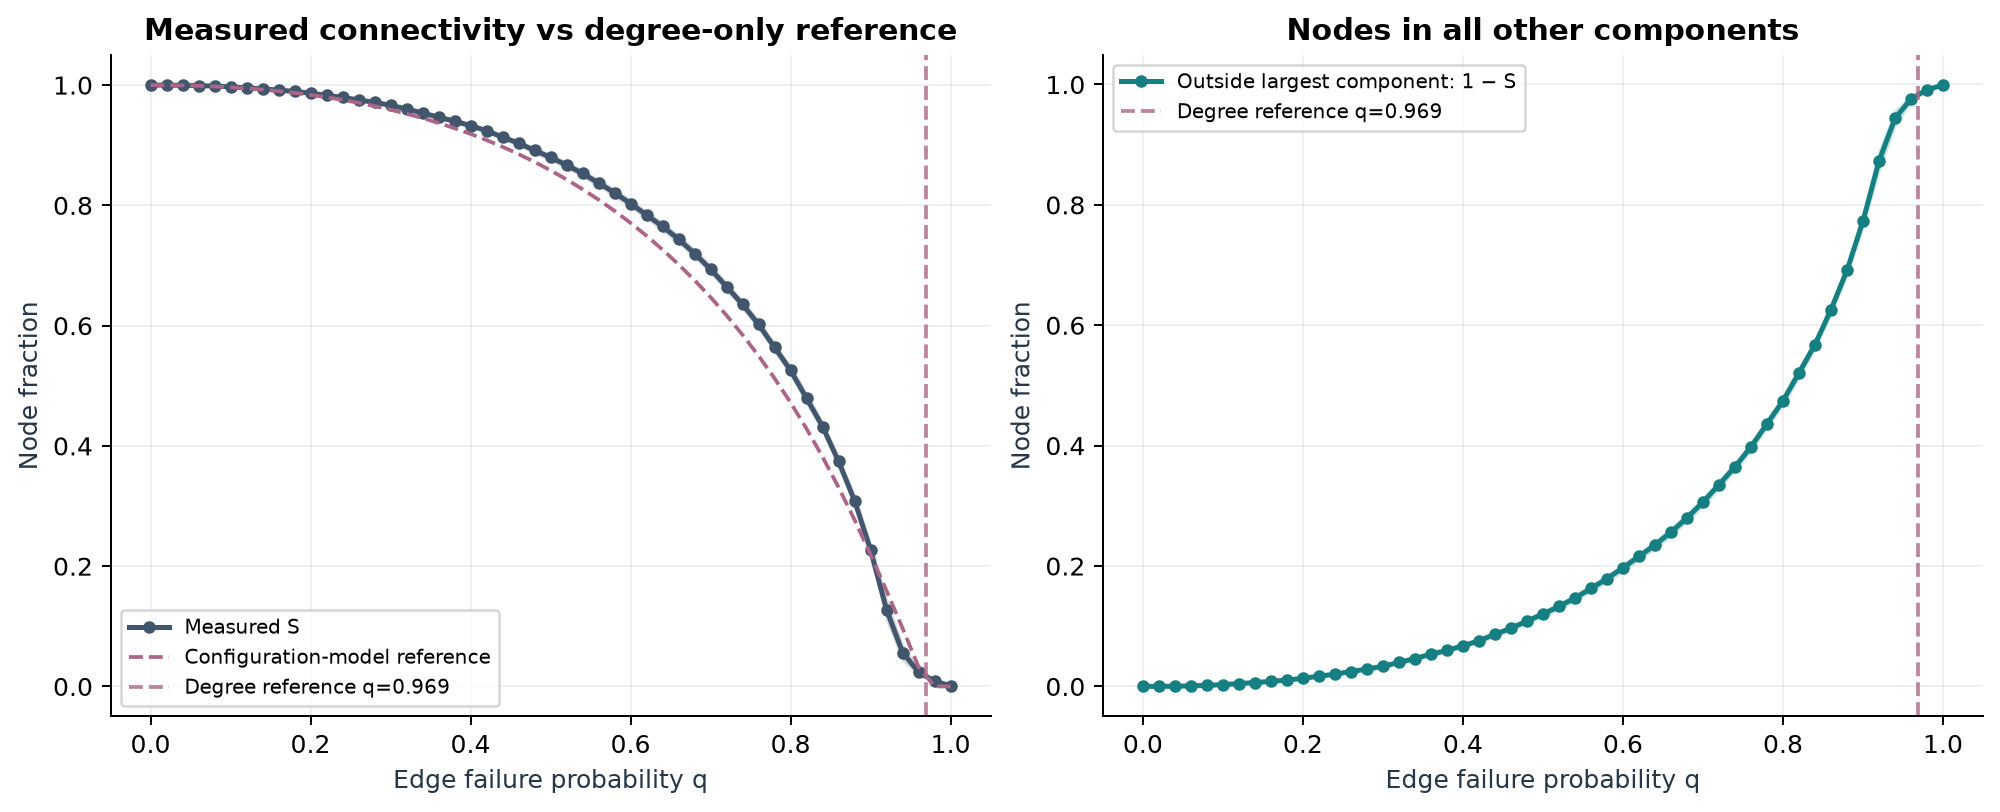

In [9]:
report.figure("fragmentation_reference")

### 7. Initial handoff for the edge-protection section

The next member can reuse this section's fixed workload and failure scenarios, while supplying their own protected-edge sets. No selection strategy is implemented or evaluated here.

| Input / interface | What to reuse |
| --- | --- |
| Frozen graph | `data/processed/nodes.csv` and `edges.csv`; verify the hashes in `data/percolation/manifest.json`. Retain all 1,000 nodes. |
| Queries | `data/percolation/queries.csv`: the same 150 unordered pairs and original distances. Do not resample by strategy. |
| Edge identity | `data/percolation/edge_order.csv`: canonical unordered endpoint pairs, indexed by edge ID. |
| Failure scenarios | `data/percolation/failure_uniforms.npy`, shape (30, 3417). Row r corresponds to repetition r; column e follows the saved edge order. |
| Damage interface | `src/percolation/core.py::damage_graph(graph, edges, uniforms[r], q, protected_edges=...)`. The optional set contains canonical endpoint pairs from the original graph. Unknown edges are rejected. |
| Evaluation | `src/percolation/core.py::evaluate(damaged_graph, queries)` returns Q, Q₂, Q₃, S, the outside-largest fraction, and per-query outcomes. |
| Baseline | `data/percolation/runs.csv` contains the 330 baseline scenarios. Match repetition and q when comparing methods. |

**Failure rule:** remove an edge only when its existing draw is below q **and** the edge is not in the supplied set. Do not skip random draws or generate new values for each method. With an empty set, the interface reproduces the baseline.

NOTE: Choose edges before failures and keep the agreed budget and ranking convention consistent across methods. If the group retains a 5% budget with flooring, this graph gives 170 edges. A random allocation should use a stream independent of failures; document whether it changes across repetitions and keep it fixed across q within a repetition.

Compare methods within the same repetition and q. Reuse `src/percolation/statistics.py::mean_interval()` to summarize **paired differences**, rather than treating the individual query outcomes as independent. A gain over the baseline includes the benefit of preventing deletions; a comparison against random allocation addresses whether the allocation rule adds value.

NOTE: Protected edges can remain at q=1, so the baseline endpoint Q=0 does not apply to those experiments. The interface is a handoff facility only; the next member remains responsible for selecting and evaluating strategies.


### Conclusion — what the results support

- At q=0.5, the largest component retains **88.0%** of nodes, but only **38.2%** of queries remain within three hops. Another **40.4%** remain connected but require longer routes. Global connectivity alone therefore misses much of the query degradation.
- Originally two-hop queries retain higher availability than three-hop queries: **50.2% versus 26.3%** at q=0.5 for this workload.
- The configuration model is a degree-based reference. The “small components” curve equals **1−S** and does not establish a separate empirical threshold.
